# Exact connections and prescribed displacements: the null-space method against the penalty method

The domains of a [`MultiDomain`](../multidomain.rst) assembly are connected, and the prescribed displacements of a
[`Shell`](../shell.rst) are imposed, either with penalty stiffnesses or exactly, with the null-space method, see
[Exact connections with the null-space method](../multidomain_null_space.rst).

- **Penalty method.** For each quantity $q_k$ that must be continuous across a connection, or equal to a prescribed
  value $q_p$, the energy $\frac{1}{2} k_k \int (q_k^{(1)} - q_k^{(2)})^2$, or $\frac{1}{2} k \int (q - q_p)^2$, is
  added. The constraint is only approximate: the assembly is too flexible, its error decreases with $1/k$, and the
  condition number of the stiffness matrix grows with $k$.
- **Null-space method.** The constraints are the linear equations $\boldsymbol{B} \boldsymbol{c} = \boldsymbol{b}$ of
  the Ritz constants $\boldsymbol{c}$, solved exactly by $\boldsymbol{c} = \boldsymbol{Z} \boldsymbol{c}_r +
  \boldsymbol{c}_p$, with $\boldsymbol{Z}$ a basis of the null space of $\boldsymbol{B}$ and $\boldsymbol{c}_p$ a
  particular solution; the reduced matrices are $\boldsymbol{Z}^\top \boldsymbol{K} \boldsymbol{Z}$.

This notebook computes, for the same models with both methods, the error of the penalty method as a function of the
penalty constants, the condition numbers, and the run times. Part 1 treats the connections, `conn_method`, part 2 the
prescribed displacements, `pd_method`. The models are those of the tests `tests/multidomain/test_null_space.py`,
`test_null_space_pd.py` and `test_multidomain_fsdt_tsdt.py`, whose helper functions are imported.

**References**

- A. K. Noor, Free vibrations of multilayered composite plates, *AIAA Journal* 11(7) (1973) 1038-1039,
  [doi:10.2514/3.6868](https://doi.org/10.2514/3.6868) (the thick cross-ply plate of part 1).

In [1]:
%matplotlib inline
import os
import sys
import time
import contextlib
import io
import functools

import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import leggauss
from IPython.display import Markdown, display
from structsolve import Analysis, lb, solve
from structsolve.sparseutils import remove_null_cols, finalize_symmetric_matrix

import panels.multidomain.connections as connections
from panels.shell import Shell
from panels.multidomain import (MultiDomain, cylinder_compression_lb_Nxx_cte,
        cylinder_blade_stiffened_compression_lb_Nxx_from_static)
from panels.multidomain.connections import fkCpd, fkCld_xcte
from panels.multidomain.tstiff2d_1stiff_freq import tstiff2d_1stiff_freq

sys.path.insert(0, os.path.join('..', 'tests', 'multidomain'))
from test_multidomain_fsdt_tsdt import (CLPT, FSDT, RHO, E2, NOOR_1973, orthotropic, domains, frequencies,
                                        make_plate, sb_plates)
from test_null_space_pd import plate, end_shortening, cylinder, plate_postbuckling, E

LAMINAPROP = (142.5e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 5.1e9)


def table(headers, rows):
    lines = ['| ' + ' | '.join(headers) + ' |', '|' + '---|'*len(headers)]
    lines += ['| ' + ' | '.join(str(v) for v in row) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))


def cond(K):
    r'''2-norm condition number, the null rows and columns of the boundary conditions removed'''
    K, _ = remove_null_cols(K, silent=True)
    return np.linalg.cond(K.toarray())


_frequencies = frequencies


def frequencies(K, M, k):
    r'''frequencies of the test module, without its progress messages'''
    with contextlib.redirect_stdout(io.StringIO()):
        return _frequencies(K, M, k)


_calc_kt_kr = connections.calc_kt_kr


@contextlib.contextmanager
def penalty_factor(factor):
    r'''Default penalty constants of calc_kt_kr multiplied by factor'''
    def scaled(*args, **kwargs):
        kt, kr = _calc_kt_kr(*args, **kwargs)
        return factor*kt, (None if kr is None else factor*kr)
    connections.calc_kt_kr = scaled
    try:
        yield
    finally:
        connections.calc_kt_kr = _calc_kt_kr

## Part 1. Connections

### 1.1 Limit of the penalty method

A thin square plate, $a/h = 50$, cross-ply $[0/90/0/90]$ with $E_1/E_2 = 10$, simply supported, divided in $2 \times 2$
domains with the classical laminated plate theory, ``'SSxcte'`` and ``'SSycte'`` connections and $10 \times 10$ terms
per domain. The first four natural frequencies are computed with the null-space method, the reference, and with the
penalty method, with the default constants of [`calc_kt_kr`](../multidomain_connections.rst) multiplied by 1, 10, 100
and 1000. The penalty energy is non-negative, so the penalty method can only be more flexible: its frequencies are
lower. The relative difference is $\omega_{penalty}/\omega_{null-space} - 1$.

In [2]:
a = 1.
h = a/50
panels_, conn = domains(CLPT, a, h, [0, 90, 0, 90], orthotropic(10), '2x2', factor=1.)
mdns = MultiDomain(panels_, conn, conn_method='null-space')
ref = frequencies(mdns.reduce(mdns.calc_kC()), mdns.reduce(mdns.calc_kM(silent=True)), k=4)
print('null-space, first four frequencies (rad/s):', np.round(ref, 4))
factors = [1., 10., 100., 1000.]
errors_thin = []
rows = []
for factor in factors:
    panels_, conn = domains(CLPT, a, h, [0, 90, 0, 90], orthotropic(10), '2x2', factor=factor)
    mdp = MultiDomain(panels_, conn, conn_method='penalty')
    om = frequencies(mdp.calc_kC(), mdp.calc_kM(silent=True), k=4)
    err = om/ref - 1
    errors_thin.append(np.abs(err).max())
    rows.append(['%g' % factor] + ['%.4f (%+.2e)' % (o, e) for o, e in zip(om, err)])
table(['penalty factor'] + ['mode %d (diff.)' % (i + 1) for i in range(4)], rows)

null-space, first four frequencies (rad/s): [164.5423 449.75   449.75   657.4317]


| penalty factor | mode 1 (diff.) | mode 2 (diff.) | mode 3 (diff.) | mode 4 (diff.) |
|---|---|---|---|---|
| 1 | 162.4068 (-1.30e-02) | 447.0380 (-6.03e-03) | 447.0421 (-6.02e-03) | 654.2168 (-4.89e-03) |
| 10 | 164.3231 (-1.33e-03) | 449.4689 (-6.25e-04) | 449.4689 (-6.25e-04) | 657.0957 (-5.11e-04) |
| 100 | 164.5204 (-1.34e-04) | 449.7218 (-6.27e-05) | 449.7218 (-6.27e-05) | 657.3980 (-5.13e-05) |
| 1000 | 164.5401 (-1.34e-05) | 449.7472 (-6.28e-06) | 449.7472 (-6.28e-06) | 657.4283 (-5.15e-06) |

### 1.2 Conditioning

Four curved panels, $r = 10$ m, $[0/45/-45/90/-45/45/0]$, $10 \times 10$ terms each, connected by ``'SSxcte'`` and
``'SSycte'``, with $u = v = w = 0$ and the rotations free at the outer edges, against the single panel with
$13 \times 13$ terms. The 2-norm condition number of the stiffness matrix of the penalty method, with the default
constants and with 100 times higher ones, is compared with that of the reduced stiffness matrix
$\boldsymbol{Z}^\top \boldsymbol{K} \boldsymbol{Z}$ of the null-space method; the first natural frequency is compared
with the single panel.

In [3]:
plyt = 0.125e-3
stack = [0, 45, -45, 90, -45, 45, 0]
kw = dict(r=10., m=10, n=10, plyt=plyt, stack=stack, laminaprop=LAMINAPROP, rho=1.3e3, group='panels')
a1, a3, b1, b2 = 1.5, 2.5, 1.5, 0.5


def set_edges(p, outer):
    for e in ('x1', 'x2', 'y1', 'y2'):
        for f in ('u', 'v', 'w'):
            setattr(p, e + f, 0. if e in outer else 1.)
            setattr(p, e + f + 'r', 1.)


def four_panels(conn_method, factor=1.):
    p01 = Shell(x0=a3, y0=b2, a=a1, b=b1, **kw)
    p02 = Shell(x0=a3, y0=0, a=a1, b=b2, **kw)
    p03 = Shell(x0=0, y0=b2, a=a3, b=b1, **kw)
    p04 = Shell(x0=0, y0=0, a=a3, b=b2, **kw)
    for p, outer in ((p01, 'x2 y2'), (p02, 'x2 y1'), (p03, 'x1 y2'), (p04, 'x1 y1')):
        set_edges(p, outer.split())
    conn = []
    for pA, pB, func in ((p01, p02, 'SSycte'), (p01, p03, 'SSxcte'), (p02, p04, 'SSxcte'), (p03, p04, 'SSycte')):
        kt, kr = connections.calc_kt_kr(pA, pB, func[2:])
        d = dict(p1=pA, p2=pB, func=func, kt=factor*kt, kr=factor*kr)
        d.update(dict(ycte1=0, ycte2=pB.b) if func == 'SSycte' else dict(xcte1=0, xcte2=pB.a))
        conn.append(d)
    return MultiDomain([p01, p02, p03, p04], conn, conn_method=conn_method)


single = Shell(a=a1 + a3, b=b1 + b2, **dict(kw, m=13, n=13))
om_single = frequencies(single.calc_kC(), single.calc_kM(), k=1)[0]
rows = []
res_cond = {}
for label, method, factor in (('penalty, default constants', 'penalty', 1.),
                              ('penalty, 100 times', 'penalty', 100.),
                              ('null-space', 'null-space', 1.)):
    mdc = four_panels(method, factor)
    K = mdc.reduce(mdc.calc_kC())
    M = mdc.reduce(mdc.calc_kM(silent=True))
    res_cond[label] = cond(K)
    om = frequencies(K, M, k=1)[0]
    rows.append([label, K.shape[0], '%.2e' % res_cond[label], '%.4f' % om, '%+.2e' % (om/om_single - 1)])
table(['model', 'size', 'condition number', '$\\omega_1$ (rad/s)', 'diff. vs single panel'], rows)
print('single panel, 13 x 13 terms: omega_1 = %.4f rad/s' % om_single)
for label in list(res_cond)[:2]:
    print('%s: condition number %.0f times that of the null-space method'
          % (label, res_cond[label]/res_cond['null-space']))

| model | size | condition number | $\omega_1$ (rad/s) | diff. vs single panel |
|---|---|---|---|---|
| penalty, default constants | 1200 | 7.00e+16 | 53.0405 | +1.91e-04 |
| penalty, 100 times | 1200 | 6.98e+18 | 53.0422 | +2.23e-04 |
| null-space | 1062 | 1.14e+14 | 53.0433 | +2.44e-04 |

single panel, 13 x 13 terms: omega_1 = 53.0304 rad/s
penalty, default constants: condition number 611 times that of the null-space method
penalty, 100 times: condition number 60969 times that of the null-space method


### 1.3 Thick plate with the first-order shear deformation theory

The plate of Noor (1973): square, $a/h = 5$, cross-ply $[0/90/0/90]$, $E_1/E_2 = 10$, $G_{12} = G_{13} = 0.6 E_2$,
$G_{23} = 0.5 E_2$, $\nu_{12} = 0.25$, simply supported, with the FSDT and the shear correction factor $5/6$, divided
in $2 \times 2$ domains of $10 \times 10$ terms. The reference is the single-domain plate with $14 \times 14$ terms,
whose frequency parameter $\bar{\omega} = \omega a^2/h \sqrt{\rho/E_2}$ is also compared with the FSDT value of the
literature, 8.2246, stored in `NOOR_1973` (3D elasticity: 8.1445). Difference: largest $|\omega/\omega_{ref} - 1|$ of
the first eight frequencies.

In [4]:
a = 1.
h = a/5
single = make_plate(FSDT, a, a, h, [0, 90, 0, 90], orthotropic(10), m=14, n=14)
ref8 = frequencies(single.calc_kC(), single.calc_kM(), k=8)
scale = a**2/h*np.sqrt(RHO/E2)
print('single domain: omega_bar = %.4f, literature (FSDT) %.4f, difference %+.2e'
      % (ref8[0]*scale, NOOR_1973[FSDT], ref8[0]*scale/NOOR_1973[FSDT] - 1))
res_thick = {}
rows = []
for label, method, factor in (('penalty, default constants', 'penalty', 1.),
                              ('penalty, 1000 times', 'penalty', 1000.),
                              ('null-space', 'null-space', 1.)):
    panels_, conn = domains(FSDT, a, h, [0, 90, 0, 90], orthotropic(10), '2x2', factor=factor)
    mdt = MultiDomain(panels_, conn, conn_method=method)
    om = frequencies(mdt.reduce(mdt.calc_kC()), mdt.reduce(mdt.calc_kM(silent=True)), k=8)
    res_thick[label] = np.abs(om/ref8 - 1).max()
    rows.append([label, '%.4f' % (om[0]*scale), '%.2e' % res_thick[label]])
table(['model', '$\\bar{\\omega}_1$', 'max. diff. of 8 frequencies vs single domain'], rows)

single domain: omega_bar = 8.2246, literature (FSDT) 8.2246, difference +1.77e-07


| model | $\bar{\omega}_1$ | max. diff. of 8 frequencies vs single domain |
|---|---|---|
| penalty, default constants | 7.5805 | 7.83e-02 |
| penalty, 1000 times | 8.2238 | 9.46e-05 |
| null-space | 8.2246 | 3.01e-12 |

### 1.4 Two laminates bonded with ``'SB'``

The laminates $[0/90]$ over $[0/90]$ connected over their area by ``'SB'`` are the single laminate $[0/90]_2$:
the connection ties the displacements of the faces in contact, $u_1 - z_1 w_{,x} = u_2 - z_2 w_{,x}$, $v_1 - z_1
w_{,y} = v_2 - z_2 w_{,y}$, $w_1 = w_2$, which is exactly the kinematics of the single laminate with the classical
laminated plate theory. Square plate, $a/h = 5$, CLPT, $10 \times 10$ terms, first eight frequencies.

The same holds for the geometrically non-linear analysis: a thin plate, $a/h = 50$, $8 \times 8$ terms, under a central
point load of $2 \times 10^5$ N with the von Kármán kinematics, solved with Newton-Raphson on the reduced functions of
[`MultiDomain.get_reduced_functions`](../multidomain.rst). The in-plane displacements of the edges are restrained only
in the tangential direction: restraining the normal one in both laminates, $z_1 \ne z_2$, would also clamp the
rotation of the edge.

In [5]:
rows = []
res_sb = {}
for label, factor in (('penalty, default constant', 1.), ('penalty, $10^5$ times', 1.e5), ('null-space', None)):
    mdsb, single = sb_plates(CLPT, 5, [0, 90], [0, 90], factor=factor or 1., kr_factor=1.)
    if factor is None:
        mdsb.conn_method = 'null-space'
    om = frequencies(mdsb.reduce(mdsb.calc_kC()), mdsb.reduce(mdsb.calc_kM(silent=True)), k=8)
    ref = frequencies(single.calc_kC(), single.calc_kM(), k=8)
    res_sb[label] = np.abs(om/ref - 1).max()
    rows.append([label, '%.2e' % res_sb[label]])
table(['model', 'max. diff. of 8 frequencies vs $[0/90]_2$'], rows)

# non-linear, null-space
a = 1.
h = a/50
P = 2.e5


def nl_plate(stack, h):
    s = make_plate(CLPT, a, a, h, stack, orthotropic(10), m=8, n=8)
    s.nx = s.ny = 16
    return s


single = nl_plate([0, 90, 0, 90], h)
single.add_point_load(a/2, a/2, 0, 0, -P, cte=False)
an = Analysis(single.calc_fext, single.calc_fint, single.calc_kC, single.calc_kG)
an.static(NLgeom=True, silent=True)
w_ref = single.uvw(c=an.cs[-1], gridx=3, gridy=3)[1]['w'][1, 1]
c_lin = solve(single.calc_kC(), single.calc_fext(), silent=True)
w_lin = single.uvw(c=c_lin, gridx=3, gridy=3)[1]['w'][1, 1]
top = nl_plate([0, 90], h/2)
bot = nl_plate([0, 90], h/2)
top.add_point_load(a/2, a/2, 0, 0, -P, cte=False)
mdnl = MultiDomain([top, bot], [dict(p1=top, p2=bot, func='SB')], conn_method='null-space')
an = Analysis(*mdnl.get_reduced_functions())
an.static(NLgeom=True, silent=True)
w = mdnl.uvw(mdnl.expand(an.cs[-1]), group=None, eval_panel=top, gridx=3, gridy=3)['w'][0][1, 1]
res_sb_nl = w/w_ref - 1
table(['model', 'central deflection (m)', 'diff. vs $[0/90]_2$'],
      [['$[0/90]_2$, linear', '%.6f' % w_lin, '-'], ['$[0/90]_2$, non-linear', '%.6f' % w_ref, '-'],
       ["``'SB'``, null-space, non-linear", '%.6f' % w, '%+.1e' % res_sb_nl]])

| model | max. diff. of 8 frequencies vs $[0/90]_2$ |
|---|---|
| penalty, default constant | 3.09e-01 |
| penalty, $10^5$ times | 6.94e-06 |
| null-space | 6.98e-13 |

| model | central deflection (m) | diff. vs $[0/90]_2$ |
|---|---|---|
| $[0/90]_2$, linear | -1.045226 | - |
| $[0/90]_2$, non-linear | -0.117578 | - |
| ``'SB'``, null-space, non-linear | -0.117578 | -2.7e-15 |

### 1.5 Cylinders and a stiffened panel

Three assemblies of `panels.multidomain`, whose functions take the argument `conn_method`; the higher penalty
constants are obtained by multiplying those of `calc_kt_kr` (`penalty_factor` above):

- closed cylinder of 5 panels, $r = 0.25$ m, height 0.5 m, $[0/45/-45/90/-45/45]$, $8 \times 12$ terms, buckling
  under a uniform $N_{xx}$, [`cylinder_compression_lb_Nxx_cte`](../multidomain.rst);
- the same cylinder with 5 blades of the model `'plate_clpt_gl'`, $[0/90/0]_4$, 20 mm high, buckling with the
  pre-buckling state of a static
  analysis, `cylinder_blade_stiffened_compression_lb_Nxx_from_static`;
- a T-stiffened panel, ``'SSxcte'``, ``'SSycte'``, ``'SB'`` and ``'BFycte'``, the base and the skin with different
  numbers of terms, first natural frequency, `tstiff2d_1stiff_freq`.

Difference: relative to the null-space method.

In [6]:
cyl = dict(height=0.5, r=0.25, plyt=0.125e-3, stack=[0, 45, -45, 90, -45, 45], laminaprop=LAMINAPROP, npanels=5,
           m=8, n=12, num_eigvalues=10)


def closed_cylinder(method):
    Nxxs = [-100.]*5
    _, ev, _ = cylinder_compression_lb_Nxx_cte(Nxxs=Nxxs, conn_method=method, **cyl)
    return Nxxs[0]*np.real(ev[0])


def blade_cylinder(method):
    Nxxs = [-100.]*5
    _, _, ev, _ = cylinder_blade_stiffened_compression_lb_Nxx_from_static(stack_blades=[[0, 90, 0]*4]*5,
        width_blades=[0.02]*5, Nxxs_skin=Nxxs, Nxxs_blade=Nxxs, conn_method=method, **cyl)
    return Nxxs[0]*np.real(ev[0])


def tstiff(method):
    _, ev, _ = tstiff2d_1stiff_freq(b=1., bb=0.2, bf=0.1, a=3., ys=0.5, defect_a=0.1, rho=1.3e3, plyt=0.125e-3,
        laminaprop=LAMINAPROP, stack_skin=[0, 45, -45, 90, -45, 45, 0], stack_base=[0, 90, 0]*4,
        stack_flange=[0, 90, 0]*8, m=6, n=7, mb=5, nb=6, mf=6, nf=7, num_eigvalues=10, conn_method=method)
    return np.real(-ev[0])**0.5


res_assy = {}
for name, func, factor in (('closed cylinder, $N_{xx}$ (N/m)', closed_cylinder, None),
                           ('blade-stiffened cylinder, $N_{xx}$ (N/m)', blade_cylinder, 1000.),
                           ('T-stiffened panel, $\\omega_1$ (rad/s)', tstiff, 100.)):
    t0 = time.time()
    r = {'default': func('penalty'), 'null-space': func('null-space')}
    if factor is not None:
        with penalty_factor(factor):
            r[factor] = func('penalty')
    res_assy[name] = r
    print('%s: %.0f s' % (name, time.time() - t0))
rows = []
for name, r in res_assy.items():
    ns = r['null-space']
    row = [name, '%.4f (%+.2e)' % (r['default'], r['default']/ns - 1)]
    high = [k for k in r if not isinstance(k, str)]
    row.append('%.4f (%+.2e), %g times' % (r[high[0]], r[high[0]]/ns - 1, high[0]) if high else '-')
    row.append('%.4f' % ns)
    rows.append(row)
table(['case', 'penalty, default constants (diff.)', 'penalty, higher constants (diff.)', 'null-space'], rows)

closed cylinder, $N_{xx}$ (N/m): 1 s


/home/saullogiovanip/align2026/runs/w7FBnb-20261106-091857/tmp/ipykernel_102965/3168506151.py:13: DenseFallbackWarning: Linear buckling analysis: the sparse solvers failed (eigsh() in Cayley mode: relative residual 1.25e-03 > 1.0e-03 for the load multiplier 419.2586906340729; eigsh() in Cayley mode with a 10 times larger shift: relative residual 1.30e-02 > 1.0e-03 for the load multiplier 419.2443281122749), using the dense solver eigh() with condensed dofs of size 1860 as a last resort
  _, _, ev, _ = cylinder_blade_stiffened_compression_lb_Nxx_from_static(stack_blades=[[0, 90, 0]*4]*5,


blade-stiffened cylinder, $N_{xx}$ (N/m): 7 s


T-stiffened panel, $\omega_1$ (rad/s): 1 s


| case | penalty, default constants (diff.) | penalty, higher constants (diff.) | null-space |
|---|---|---|---|
| closed cylinder, $N_{xx}$ (N/m) | -47055.9833 (-1.21e-03) | - | -47113.0395 |
| blade-stiffened cylinder, $N_{xx}$ (N/m) | -39992.2232 (-4.08e-02) | -41692.9107 (-4.35e-05), 1000 times | -41694.7250 |
| T-stiffened panel, $\omega_1$ (rad/s) | 48.4404 (-2.53e-03) | 48.5611 (-4.06e-05), 100 times | 48.5631 |

### Summary of part 1

The error of the penalty method decreases as $1/k$ (section 1.1, plotted below) and the condition number grows with
$k$ (section 1.2); the null-space method gives the limit $k \to \infty$ without any penalty constant, e.g. the single
laminate with ``'SB'`` to round-off, also in the non-linear analysis (section 1.4).

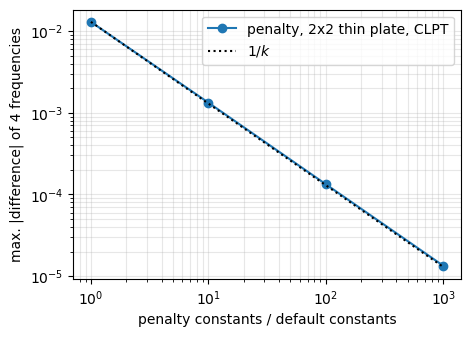

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.loglog(factors, errors_thin, 'o-', label='penalty, 2x2 thin plate, CLPT')
ax.loglog(factors, errors_thin[0]/np.array(factors), 'k:', label='$1/k$')
ax.set_xlabel('penalty constants / default constants')
ax.set_ylabel('max. |difference| of 4 frequencies')
ax.grid(alpha=0.3, which='both')
ax.legend()
plt.show()

## Part 2. Prescribed displacements

With the penalty method a prescribed displacement $u_p$ is the energy $\frac{1}{2} k \int (u - u_p)^2$, a spring of
stiffness $k$ between the structure and the support: the structure is more flexible, the prescribed value is not
reached, the error decreases with $1/k$ and the condition number grows with $k$. The penalty stiffnesses are those of
[`fkCld_xcte`](../multidomain_connections.rst) and [`fkCpd`](../multidomain_connections.rst), added to the stiffness
matrix. With `pd_method='null-space'` the prescriptions are the inhomogeneous constraints
$\boldsymbol{c} = \boldsymbol{Z} \boldsymbol{c}_r + \boldsymbol{c}_{p0} + \lambda \boldsymbol{c}_{p1}$, and the
reaction is $\boldsymbol{c}_{p}^\top \boldsymbol{r}$ with the residual $\boldsymbol{r}$ of the unconstrained system,
see [`MultiDomain.reaction_resultant`](../multidomain.rst).

### 2.1 Linear static analysis: accuracy and conditioning

Isotropic plate, $E = 70$ GPa, $\nu = 0.3$, $a = 1$ m, $b = 0.6$ m, $h = 2$ mm, CLPT, $10 \times 10$ terms, $w = 0$
at the edges, under a uniform end-shortening $\delta = 1$ mm, $u = 0$ at $x = 0$ and $u = -\delta$ at $x = a$, with
the lateral contraction restrained along $y = 0, b$, a non-uniform membrane state. The penalty constant $k$ is given
relative to the membrane stiffness $E h$. The reaction of the penalty method, $k \int (u_p - u) dy$, is integrated with
40 Gauss-Legendre points along $x = a$. Differences: $\|\boldsymbol{c} - \boldsymbol{c}_{ns}\|/\|\boldsymbol{c}_{ns}\|$
and $F/F_{ns} - 1$.

Ritz constants 300, independent 280; axial reaction F_ns = -92307.69 N (-E h b delta/a = -84000.00 N with the lateral contraction free)
condition number of the reduced stiffness matrix: 1.36e+11


| $k/(E h)$ | 1e+01 | 1e+02 | 1e+04 | 1e+06 | 1e+08 | 1e+10 |
|---|---|---|---|---|---|---|
| diff. of $\boldsymbol{c}$ | 1.6e-01 | 2.0e-02 | 2.0e-04 | 2.0e-06 | 2.0e-08 | 3.0e-09 |
| diff. of the reaction | -1.8e-01 | -2.2e-02 | -2.2e-04 | -2.2e-06 | -2.2e-08 | -1.2e-06 |
| condition number | 2.5e+12 | 2.0e+13 | 2.0e+15 | 2.1e+17 | 1.8e+19 | 1.8e+21 |

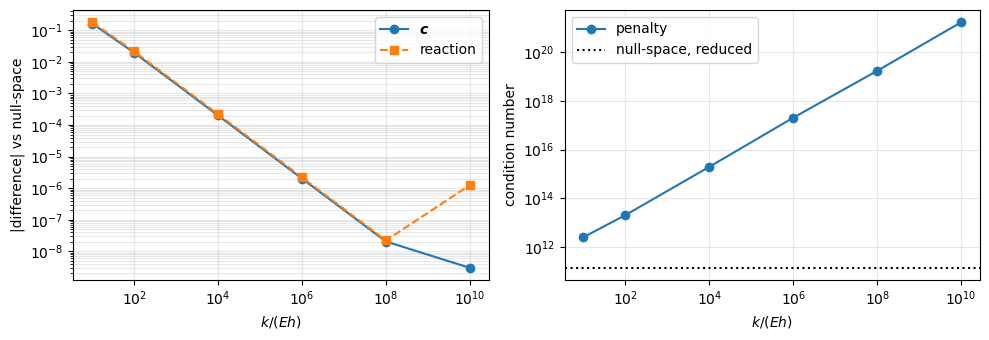

In [8]:
a, b, delta, h = 1., 0.6, 1e-3, 2e-3
p = plate(a, b, h=h, m=10, n=10)
p.y1v = p.y2v = 0.
end_shortening(p, delta)
p.add_point_pd(0., 0., 0, None, 1., 0., 0, None)
mdpd = MultiDomain([p], conn=[], pd_method='null-space')
c_ns = mdpd.linear_static()
F_ns = mdpd.reaction_resultant(c_ns, [(p, 'x', p.a)], NLgeom=False)[0]
Z = mdpd.get_Z()
cond_ns = cond(mdpd.reduce(mdpd.calc_kC()))
print('Ritz constants %d, independent %d; axial reaction F_ns = %.2f N (-E h b delta/a = %.2f N with the lateral contraction free)'
      % (Z.shape[0], Z.shape[1], F_ns, -E*h*b*delta/a))
print('condition number of the reduced stiffness matrix: %.2e' % cond_ns)


def penalty_system(p, delta, k):
    p.clear_disps()
    end_shortening(p, delta)
    p.add_point_pd(0., 0., 0., 0., k, 0., 0., 0.)
    for pd in p.distr_pds + p.distr_pds_inc:
        pd[2] = (lambda f: (lambda y: k*f(y)))(pd[2])
    mdp = MultiDomain([p], conn=[])
    size = mdp.get_size()
    kCp = finalize_symmetric_matrix(fkCld_xcte(k, 0., 0., p, 0., size, 0, 0)
                                    + fkCld_xcte(k, 0., 0., p, p.a, size, 0, 0)
                                    + fkCpd(0., k, 0., p, 0., 0., size, 0, 0))
    return mdp.calc_kC() + kCp, mdp.calc_fext()


eta, wg = leggauss(40)
ys = (eta + 1)*p.b/2
kfactors = [1e1, 1e2, 1e4, 1e6, 1e8, 1e10]
res_static = []
for kf in kfactors:
    k = kf*E*h
    K, f = penalty_system(p, delta, k)
    c = solve(K, f, silent=True)
    _, fl = p.uvw(c, xs=np.full_like(ys, p.a), ys=ys)
    F = k*np.dot(wg, -delta - fl['u'])*p.b/2
    res_static.append((np.linalg.norm(c - c_ns)/np.linalg.norm(c_ns), F/F_ns - 1, cond(K)))
table(['$k/(E h)$'] + ['%.0e' % kf for kf in kfactors],
      [['diff. of $\\boldsymbol{c}$'] + ['%.1e' % r[0] for r in res_static],
       ['diff. of the reaction'] + ['%+.1e' % r[1] for r in res_static],
       ['condition number'] + ['%.1e' % r[2] for r in res_static]])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].loglog(kfactors, [r[0] for r in res_static], 'o-', label='$\\boldsymbol{c}$')
ax[0].loglog(kfactors, [abs(r[1]) for r in res_static], 's--', label='reaction')
ax[0].set_ylabel('|difference| vs null-space')
ax[1].loglog(kfactors, [r[2] for r in res_static], 'o-', label='penalty')
ax[1].axhline(cond_ns, color='k', ls=':', label='null-space, reduced')
ax[1].set_ylabel('condition number')
for axi in ax:
    axi.set_xlabel('$k/(E h)$')
    axi.grid(alpha=0.3, which='both')
    axi.legend()
plt.tight_layout()
plt.show()

### 2.2 Linear buckling under an end-shortening

Cylinder of 5 panels of section 1.5, simply supported, under a uniform end-shortening $\delta$ at $x = a$. $\delta$ is
that of the linear static solution under $N_{xx} = -100$ N/m. The critical end-shortening of the null-space method is
the reference; the penalty method, with $k$ relative to the membrane stiffness $A_{11}$ of the laminate, shortens the
cylinder less than the prescribed value and its critical end-shortening is higher. The time is that of the whole
analysis, from the creation of the model to the critical end-shortening, measured on the machine that executed this
notebook.

In [9]:
Nxx = -100.
mdc = cylinder('null-space')
for pc in mdc.panels:
    pc.add_distr_load_fixed_x(pc.a, lambda y: Nxx, None, None)
c_N = mdc.linear_static()
mesh, fl = mdc.panels[0].uvw(c_N[mdc.panels[0].col_start:mdc.panels[0].col_end], gridx=7, gridy=5)
delta_c = -fl['u'][0, -1]
print('end-shortening under Nxx = %.0f N/m: %.4e m' % (Nxx, delta_c))

t0 = time.perf_counter()
mdc = cylinder('null-space')
for pc in mdc.panels:
    pc.add_distr_pd_fixed_x(pc.a, ku=1., funcu=lambda y: -delta_c, cte=False)
eig_d, _ = mdc.linear_buckling(num_eigvalues=3)
t_ns = time.perf_counter() - t0
rows = [['null-space', '%.6f' % eig_d[0], '-', '%.2f s' % t_ns]]
cfactors = [1e1, 1e2, 1e3, 1e4, 1e6]
res_cyl = []
for kf in cfactors:
    t0 = time.perf_counter()
    mdc = cylinder('penalty')
    size = mdc.get_size()
    k = kf*mdc.panels[0].lam.ABD[0, 0]
    kCp = 0.
    for pc in mdc.panels:
        pc.add_distr_pd_fixed_x(pc.a, ku=k, funcu=lambda y: -delta_c, cte=False)
        kCp = kCp + fkCld_xcte(k, 0., 0., pc, pc.a, size, pc.row_start, pc.col_start)
    K = mdc.calc_kC(silent=True) + finalize_symmetric_matrix(kCp)
    c = mdc.expand(solve(mdc.reduce(K), mdc.reduce(mdc.calc_fext()), silent=True))
    eig, _ = lb(mdc.reduce(K), mdc.reduce(mdc.calc_kG(c=c, silent=True)), silent=True, num_eigvalues=3)
    t = time.perf_counter() - t0
    res_cyl.append(eig[0]/eig_d[0] - 1)
    rows.append(['penalty, $k/A_{11}$ = %.0e' % kf, '%.6f' % eig[0], '%+.1e' % res_cyl[-1], '%.2f s' % t])
table(['method', 'critical $\\lambda$ ($\\delta_{cr}/\\delta$)', 'diff. vs null-space', 'time'], rows)

end-shortening under Nxx = -100 N/m: 1.4719e-06 m


/home/saullogiovanip/miniconda3/lib/python3.12/site-packages/IPython/core/interactiveshell.py:3747: DenseFallbackWarning: Linear buckling analysis: the sparse solvers failed (eigsh() in Cayley mode: relative residual 9.12e-03 > 1.0e-03 for the load multiplier 496.2335530274024; eigsh() in Cayley mode with a 10 times larger shift: relative residual 5.02e-02 > 1.0e-03 for the load multiplier 496.2335528031236), using the dense solver eigh() with condensed dofs of size 630 as a last resort
  exec(code_obj, self.user_global_ns, self.user_ns)


| method | critical $\lambda$ ($\delta_{cr}/\delta$) | diff. vs null-space | time |
|---|---|---|---|
| null-space | 490.159556 | - | 0.81 s |
| penalty, $k/A_{11}$ = 1e+01 | 560.383354 | +1.4e-01 | 1.01 s |
| penalty, $k/A_{11}$ = 1e+02 | 496.559014 | +1.3e-02 | 0.92 s |
| penalty, $k/A_{11}$ = 1e+03 | 490.787630 | +1.3e-03 | 0.86 s |
| penalty, $k/A_{11}$ = 1e+04 | 490.222234 | +1.3e-04 | 0.89 s |
| penalty, $k/A_{11}$ = 1e+06 | 490.160183 | +1.3e-06 | 1.56 s |

### 2.3 Geometrically non-linear analysis and the convergence criterion

Post-buckling of a simply supported isotropic plate, $a = 0.3$ m, $b = 0.2$ m, $h = 1$ mm, $8 \times 8$ terms, at twice
the critical end-shortening of its linear buckling analysis, with a lateral point load of 30 N at the centre as
imperfection, Newton-Raphson of `structsolve` with the end-shortening incremented. The axial reaction of the penalty
method is compared with that of the null-space method, for $k/(E h) = 10^2$ to $10^8$, with two convergence criteria of
`structsolve.Analysis`: Crisfield's, `convergence = 'crisfield'` (the default, `relTOL = 1e-9`), and the relative one,
`'relative'`.

Both criteria compare the norm of the residual with the largest norm of the references $\lambda \boldsymbol{F}_{ext}$,
$\boldsymbol{F}_{int}$ and, under displacement control, $\lambda \partial \boldsymbol{R}/\partial \lambda$. For the
penalty method $\lambda \boldsymbol{F}_{ext}$ and $\boldsymbol{F}_{int}$ contain the penalty forces $k u_p$: the
relative criterion measures them with the Euclidean norm, which grows with $k$, whereas Crisfield's criterion uses the
norm $\|\boldsymbol{v}\|_{\boldsymbol{d}} = (\sum_j v_j^2/|d_j|)^{1/2}$ scaled by the diagonal $\boldsymbol{d}$ of the
linear stiffness matrix, which contains the penalty stiffness, so that the scaled penalty forces grow only with
$\sqrt{k}$. The null-space method has no penalty forces, its reference being $\lambda \partial \boldsymbol{R}_r/\partial
\lambda$. The number of evaluations of the internal force vector and of the tangent stiffness matrix is counted.

null-space reaction: -1331.3816 N, largest relative spread over the four criteria: 2.2e-10


| criterion, $k/(E h)$ | 1e+02 | 1e+04 | 1e+06 | 1e+08 |
|---|---|---|---|---|
| ``'crisfield'``, ``relTOL = 1e-09`` | -3.6e-02 (35) | -3.8e-04 (33) | -3.8e-06 (31) | -4.2e-08 (31) |
| ``'crisfield'``, ``relTOL = 1e-06`` | -3.6e-02 (31) | -4.0e-04 (30) | -1.9e-05 (25) | -1.5e-05 (23) |
| ``'relative'``, ``relTOL = 1e-06`` | -3.6e-02 (28) | -5.5e-04 (19) | -2.1e-01 (12) | +1.1e+00 (8) |
| ``'relative'``, ``relTOL = 1e-10`` | -3.6e-02 (34) | -3.8e-04 (31) | -1.9e-05 (29) | -1.7e-04 (19) |

in parentheses: evaluations of the internal force vector


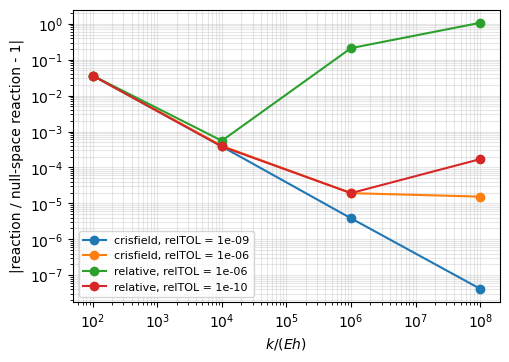

In [10]:
CRITERIA = [('crisfield', 1e-9), ('crisfield', 1e-6), ('relative', 1e-6), ('relative', 1e-10)]


def null_space_run(criterion, relTOL):
    md2, p2, d2 = plate_postbuckling(delta_factor=2., m=8, n=8, P=30.)
    fext, fint, kC, kG = md2.get_reduced_functions()
    n = {'fint': 0, 'kC': 0}

    @functools.wraps(fint)
    def cfint(*args, **kwargs):
        n['fint'] += 1
        return fint(*args, **kwargs)

    @functools.wraps(kC)
    def ckC(*args, **kwargs):
        n['kC'] += 1
        return kC(*args, **kwargs)

    an = Analysis(fext, cfint, ckC, kG)
    an.convergence = criterion
    an.relTOL = relTOL
    t0 = time.perf_counter()
    an.static(NLgeom=True, silent=True)
    t = time.perf_counter() - t0
    c = md2.expand(an.cs[-1], 1.)
    F = md2.reaction_resultant(c, [(p2, 'x', p2.a)])[0]
    return dict(F=F, t=t, inc=len(an.increments), lbd=an.increments[-1], **n)


def penalty_run(kf, criterion, relTOL):
    _, p2, d2 = plate_postbuckling(delta_factor=2., m=8, n=8, P=30.)
    k = kf*E*p2.plyt
    mdp = MultiDomain([p2], conn=[])
    p2.clear_disps()
    p2.add_distr_pd_fixed_x(0., ku=k, funcu=lambda y: 0.)
    p2.add_distr_pd_fixed_x(p2.a, ku=k, funcu=lambda y: -d2)
    p2.add_point_pd(0., 0., 0., 0., k, 0., 0., 0.)
    size = mdp.get_size()
    kCp = finalize_symmetric_matrix(fkCld_xcte(k, 0., 0., p2, 0., size, 0, 0)
                                    + fkCld_xcte(k, 0., 0., p2, p2.a, size, 0, 0)
                                    + fkCpd(0., k, 0., p2, 0., 0., size, 0, 0))
    n = {'fint': 0, 'kC': 0}

    def fint(c, silent=True):
        n['fint'] += 1
        return mdp.calc_fint(c) + kCp @ c

    def kC(c=None, NLgeom=False, silent=True):
        n['kC'] += 1
        return mdp.calc_kC(c=c, NLgeom=NLgeom) + kCp

    an = Analysis(lambda inc=1., silent=True: mdp.calc_fext(inc=inc), fint, kC,
                  lambda c=None, NLgeom=False, silent=True: mdp.calc_kG(c=c, NLgeom=NLgeom, silent=True))
    an.convergence = criterion
    an.relTOL = relTOL
    t0 = time.perf_counter()
    an.static(NLgeom=True, silent=True)
    t = time.perf_counter() - t0
    eta, wg = leggauss(40)
    ys = (eta + 1)*p2.b/2
    _, fl = p2.uvw(an.cs[-1], xs=np.full_like(ys, p2.a), ys=ys)
    F = k*np.dot(wg, -d2 - fl['u'])*p2.b/2
    return dict(F=F, t=t, inc=len(an.increments), lbd=an.increments[-1], **n)


ns = {crit: null_space_run(*crit) for crit in CRITERIA}
F_ref = ns[('crisfield', 1e-9)]['F']
spread = max(abs(r['F']/F_ref - 1) for r in ns.values())
print('null-space reaction: %.4f N, largest relative spread over the four criteria: %.1e' % (F_ref, spread))
nl_factors = [1e2, 1e4, 1e6, 1e8]
pen = {(kf, crit): penalty_run(kf, *crit) for kf in nl_factors for crit in CRITERIA}
rows = []
for crit in CRITERIA:
    rows.append(["``'%s'``, ``relTOL = %g``" % crit]
                + ['%+.1e (%d)' % (pen[(kf, crit)]['F']/F_ref - 1, pen[(kf, crit)]['fint']) for kf in nl_factors])
table(['criterion, $k/(E h)$'] + ['%.0e' % kf for kf in nl_factors], rows)
print('in parentheses: evaluations of the internal force vector')
fig, ax = plt.subplots(figsize=(5.5, 3.8))
for crit in CRITERIA:
    ax.loglog(nl_factors, [abs(pen[(kf, crit)]['F']/F_ref - 1) for kf in nl_factors], 'o-',
              label="%s, relTOL = %g" % crit)
ax.set_xlabel('$k/(E h)$')
ax.set_ylabel('|reaction / null-space reaction - 1|')
ax.grid(alpha=0.3, which='both')
ax.legend(fontsize=8)
plt.show()

### 2.4 Run times of the non-linear analysis

Run time of `Analysis.static` for the analysis of section 2.3, median of 5 runs, with the null-space method and with
the penalty method with $k/(E h) = 10^4$, measured on the machine that executed this notebook, with the numbers of
evaluations of the internal force vector and of the tangent stiffness matrix. The null-space method also needs
$\partial \boldsymbol{R}_r/\partial \lambda = -\boldsymbol{Z}^\top (\boldsymbol{F}_{ext} - \boldsymbol{K}_T
\boldsymbol{c}_{p1})$, whose product $\boldsymbol{K}_T \boldsymbol{c}_{p1}$ is computed without assembling
$\boldsymbol{K}_T$, at about the cost of one internal force vector, see [`Shell.calc_kTv`](../shell.rst).

In [11]:
rows = []
for crit in CRITERIA[:1] + CRITERIA[2:]:
    for label, func in (('null-space', lambda: null_space_run(*crit)),
                        ('penalty, $k/(E h) = 10^4$', lambda: penalty_run(1e4, *crit))):
        runs = [func() for _ in range(5)]
        r = runs[0]
        rows.append([label, "``'%s'``, ``relTOL = %g``" % crit, '%.3f s' % np.median([x['t'] for x in runs]),
                     r['inc'], r['fint'], r['kC']])
table(['method', 'criterion', 'time (median of 5)', 'increments', '$\\boldsymbol{F}_{int}$ evaluations',
       '$\\boldsymbol{K}_T$ evaluations'], rows)

| method | criterion | time (median of 5) | increments | $\boldsymbol{F}_{int}$ evaluations | $\boldsymbol{K}_T$ evaluations |
|---|---|---|---|---|---|
| null-space | ``'crisfield'``, ``relTOL = 1e-09`` | 1.952 s | 8 | 37 | 30 |
| penalty, $k/(E h) = 10^4$ | ``'crisfield'``, ``relTOL = 1e-09`` | 1.494 s | 8 | 33 | 26 |
| null-space | ``'relative'``, ``relTOL = 1e-06`` | 1.305 s | 8 | 31 | 24 |
| penalty, $k/(E h) = 10^4$ | ``'relative'``, ``relTOL = 1e-06`` | 0.606 s | 8 | 19 | 12 |
| null-space | ``'relative'``, ``relTOL = 1e-10`` | 1.741 s | 8 | 39 | 32 |
| penalty, $k/(E h) = 10^4$ | ``'relative'``, ``relTOL = 1e-10`` | 1.184 s | 8 | 31 | 24 |

## Discussion

- **Connections.** The penalty method converges to the null-space method from the flexible side, with an error
  proportional to $1/k$; with the default constants of `calc_kt_kr` the error is of the order of 1% for thin plates
  and several percent for thick ones, and higher constants make the stiffness matrix ill-conditioned. The null-space
  method needs no constant and its reduced stiffness matrix is better conditioned.
- **Prescribed displacements.** The same holds for the prescribed displacements. In addition, the reaction of the
  penalty method is the product of a large constant and a small difference: for the highest constants it loses
  accuracy by cancellation, and in a non-linear analysis the penalty forces enter the reference of the convergence
  criterion, so that the error stops decreasing as $1/k$ once the tolerance dominates, more so with the relative
  criterion than with Crisfield's. The reaction of the null-space method does not depend on any constant nor, to
  round-off, on the criterion.
- **Cost.** The linear analyses cost the same with both methods; in the non-linear analysis the run time is dominated
  by the assembly of the tangent stiffness matrix with both methods.